# 第五組：財務特徵（Feature Engineering）

每個模型都透過這張特徵表看世界。每項特徵都要回答：**在週五收盤做決策的那一刻，它讀了哪些已知的資料？**
本 notebook 先寫下每項特徵的「時點契約」（回看幾天、延遲幾天），再用三種方法檢查：暖身期稽核、
扣掉封存期後重建比對、以及尺度、離散度、冗餘、持續性四個性質。它不判斷特徵能不能預測——那是 05 的工作。

參考：ML4T 第 8 章 8.1–8.6、課程範本 `etfs/03_financial_features`。

In [1]:
from nb_utils import *                                       # 共用工具
from features import make_features                           # 與管線共用同一份特徵公式
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster  # 階層式分群
from scipy.spatial.distance import squareform                # 距離矩陣轉換
style()                                                      # 圖表樣式
panel = pd.read_parquet(PROC / "panel.parquet")              # 清理後日資料
panel = panel[panel.sid.isin(STK)].sort_values(["sid", "date"])  # 只看股票
panel["avolume"] = (panel.volume / panel.adj).where(panel.valid)  # 還原成交量（無效日空值），與管線相同
panel["amount"] = panel.amount.where(panel.valid)            # 無效日成交金額設為空值
smp = pd.read_parquet(PROC / "samples.parquet")              # 管線產生的特徵
smp = smp[smp.sid.isin(STK)]                                 # 只看股票
F = [c for c in smp.columns if c.endswith("_L20")]           # 20 日版 15 項特徵
NM = {"hv5": "Volatility_5", "hv10": "Volatility_10", "hv20": "Volatility_20", "ret1": "Return_1", "ret5": "Return_5",
      "ret20": "Return_20", "hl": "High_Low_Range", "oc": "Close_Open_Range", "ma5_dist": "MA_Gap_5", "ma20_dist": "MA_Gap_20",
      "vol_ratio": "Volume_Ratio", "vol_cv": "Volume_Volatility", "amt_ratio": "Turnover", "rsi": "RSI_14", "atr_p": "ATR_14"}  # 對應文件上的名稱
short = lambda c: c.replace("_L20", "")                      # 去掉後綴
print(f"{len(F)} 項特徵：", ", ".join(NM[short(c)] for c in F))  # 印出

15 項特徵： Volatility_5, Volatility_10, Volatility_20, Return_1, Return_5, Return_20, High_Low_Range, Close_Open_Range, MA_Gap_5, MA_Gap_20, Volume_Ratio, Volume_Volatility, Turnover, RSI_14, ATR_14


## A. 時點契約（timing contract）
每項特徵都只讀「決策日 t 當天收盤以前」的資料，延遲 0 天（13:30 收盤後計算、下一交易日開盤成交）。
「表示方式」說明它是否能跨股票比較：除以股價或除以自己的平均，才能把台積電和統懋放在同一把尺上。

In [2]:
REG = pd.DataFrame([
    ("Volatility_5/10/20", "波動", "還原收盤", "5/10/20", 0, "年化比例（可比）"),
    ("Return_1/5/20", "報酬", "還原收盤", "1/5/20", 0, "對數報酬（可比）"),
    ("High_Low_Range", "區間", "t 日高低收", "1", 0, "÷ 收盤價（可比）"),
    ("Close_Open_Range", "區間", "t 日開收", "1", 0, "÷ 開盤價（可比）"),
    ("MA_Gap_5/20", "趨勢", "還原收盤", "5/20", 0, "收盤 ÷ 均線 − 1（可比）"),
    ("Volume_Ratio", "量", "還原成交量", "20", 0, "÷ 自己 20 日均量（可比）"),
    ("Volume_Volatility", "量", "還原成交量", "20", 0, "標準差 ÷ 平均（可比）"),
    ("Turnover", "量", "成交金額", "20", 0, "÷ 自己 20 日均額（可比）"),
    ("RSI_14", "動能", "還原收盤", "14", 0, "0–100（可比；簡單平均法）"),
    ("ATR_14", "區間", "還原高低收", "14", 0, "÷ 收盤價（可比）")],
    columns=["特徵", "家族", "輸入", "回看（交易日）", "延遲（交易日）", "表示方式"])  # 時點契約表
display(REG)                                                 # 顯示

,特徵,家族,輸入,回看（交易日）,延遲（交易日）,表示方式
0,Volatility_5/10/20,波動,還原收盤,5/10/20,0,年化比例（可比）
1,Return_1/5/20,報酬,還原收盤,1/5/20,0,對數報酬（可比）
2,High_Low_Range,區間,t 日高低收,1,0,÷ 收盤價（可比）
3,Close_Open_Range,區間,t 日開收,1,0,÷ 開盤價（可比）
4,MA_Gap_5/20,趨勢,還原收盤,5/20,0,收盤 ÷ 均線 − 1（可比）
5,Volume_Ratio,量,還原成交量,20,0,÷ 自己 20 日均量（可比）
6,Volume_Volatility,量,還原成交量,20,0,標準差 ÷ 平均（可比）
7,Turnover,量,成交金額,20,0,÷ 自己 20 日均額（可比）
8,RSI_14,動能,還原收盤,14,0,0–100（可比；簡單平均法）
9,ATR_14,區間,還原高低收,14,0,÷ 收盤價（可比）


## B. 暖身期稽核
移動窗口在湊滿天數之前不能有值。每檔股票上市（或資料起點）後，第一個非空值出現的位置必須 ≥ 該特徵需要的天數；
出現得更早就代表讀到了不存在的資料。

In [3]:
need = {"hv5": 5, "hv10": 10, "hv20": 20, "ret1": 1, "ret5": 5, "ret20": 20, "hl": 0, "oc": 0, "ma5_dist": 4, "ma20_dist": 19,
        "vol_ratio": 19, "vol_cv": 19, "amt_ratio": 19, "rsi": 14, "atr_p": 14}  # 第一個值最早可出現的位置（從 0 起算）
built = pd.concat([make_features(g.set_index("date"), 20).add_suffix("_L20").assign(sid=sid).reset_index()
                   for sid, g in panel.groupby("sid")])      # 在完整面板（含暖身期）重算特徵
rows = []                                                    # 收集
for sid, g in built.groupby("sid"):                          # 逐檔
    g = g.reset_index(drop=True)                             # 位置從 0 開始
    for c in F:                                              # 逐一特徵
        first = g[c].first_valid_index()                     # 第一個非空值的位置
        rows.append({"sid": sid, "feature": NM[short(c)], "first_pos": first, "need": need[short(c)]})  # 記錄
wa = pd.DataFrame(rows)                                      # 轉表
bad = wa[wa.first_pos < wa.need]                             # 太早出現值
assert bad.empty, f"暖身期內出現數值：{bad.head()}"            # 斷言
print(f"暖身稽核通過：{len(wa)} 個（股票 × 特徵）組合，沒有任何特徵在窗口湊滿前出現數值")  # 印出

暖身稽核通過：225 個（股票 × 特徵）組合，沒有任何特徵在窗口湊滿前出現數值


## C. 扣掉封存期後重建，數值不能改變
最需要檢查的是**還原權值**：我們用除權息與減資參考價「往回」調整價格，2025 年之後的除息會改變 2016 年的還原價。
只要特徵都是「比例」，這種尺度改變就會在分子分母抵消。這裡完全獨立地重做一次：只用封存期之前的公司行動事件
重建還原價、只用封存期之前的資料重算特徵，再跟管線的數值逐筆比對。任何在全樣本上擬合的轉換都會在這裡現形。

In [4]:
ev = pd.read_csv(TAB / "corporate_actions.csv", dtype={"sid": str}, parse_dates=["date"])  # 公司行動事件（含因子）
cut = panel[panel.date < HOLDOUT_START].copy()               # 只留封存期之前的資料
ev = ev[ev.date < HOLDOUT_START]                             # 只留封存期之前的事件
cut["adj2"] = 1.0                                            # 重建的調整因子
for sid, e in ev.groupby("sid"):                             # 逐檔
    m = cut.sid == sid                                       # 這檔的列
    for _, x in e.iterrows(): cut.loc[m & (cut.date < x.date), "adj2"] *= x.factor  # 事件日前的價格乘上因子
for c in ["open", "high", "low", "close"]: cut["a" + c] = cut[c] * cut.adj2  # 重建還原價
cut["avolume"] = (cut.volume / cut.adj2).where(cut.valid); cut["amount"] = cut.amount.where(cut.valid)  # 還原量與金額（無效日空值）
rb = pd.concat([make_features(g.set_index("date"), 20).add_suffix("_L20").assign(sid=sid).reset_index()
                for sid, g in cut.groupby("sid")])           # 只用封存期前資料重算特徵
cmp = smp[smp.date < HOLDOUT_START][["date", "sid"] + F].merge(rb, on=["date", "sid"], suffixes=("", "_rb"))  # 對齊比對
res = pd.DataFrame([{"feature": NM[short(c)], "max_abs_diff": (cmp[c] - cmp[c + "_rb"]).abs().max(),
                     "null_mismatch": int((cmp[c].isna() != cmp[c + "_rb"].isna()).sum())} for c in F])  # 最大差異與空值不一致數
display(res)                                                 # 顯示
assert (res.null_mismatch == 0).all() and (res.max_abs_diff < 1e-6).all(), "扣掉封存期後特徵改變"  # 斷言
print(f"{len(cmp):,} 列 × {len(F)} 項特徵完全一致（最大差異 {res.max_abs_diff.max():.1e}）：還原權值的回溯調整沒有把未來資訊帶進特徵")  # 印出

,feature,max_abs_diff,null_mismatch
0,Volatility_5,1.117162e-14,0
1,Volatility_10,3.136380e-15,0
2,Volatility_20,1.776357e-15,0
3,Return_1,4.475587e-16,0
4,Return_5,6.574602e-16,0
5,Return_20,7.077672e-16,0
6,High_Low_Range,4.024558e-16,0
7,Close_Open_Range,3.903128e-16,0
8,MA_Gap_5,6.661338e-16,0
9,MA_Gap_20,6.661338e-16,0


27,043 列 × 15 項特徵完全一致（最大差異 1.0e-11）：還原權值的回溯調整沒有把未來資訊帶進特徵


## D. 覆蓋率（隨時間）
每月有效交易日中，每項特徵非空值的比例。缺口只該出現在新上市股票的前 20 天與停牌後。

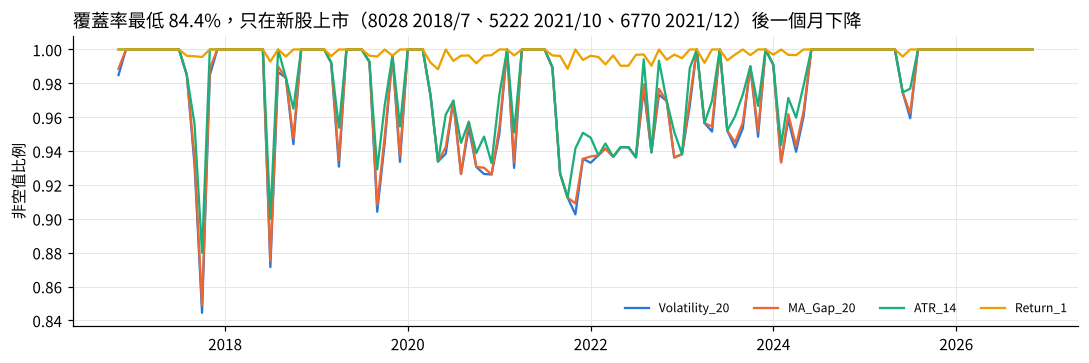

In [5]:
v = smp[smp.valid]                                           # 有效交易日
covm = v.groupby(v.date.dt.to_period("M"))[F].apply(lambda t: t.notna().mean())  # 每月覆蓋率
fig, ax = plt.subplots(figsize=(10, 3.4))                    # 開圖
for c, col in zip(["hv20_L20", "ma20_dist_L20", "atr_p_L20", "ret1_L20"], [BLUE, ORANGE, AQUA, YELLOW]):  # 代表性特徵
    ax.plot(covm.index.to_timestamp(), covm[c], color=col, lw=1.5, label=NM[short(c)])  # 線
ax.legend(frameon=False, fontsize=8, ncol=4); ax.set_ylabel("非空值比例")  # 圖例
ax.set_title(f"覆蓋率最低 {covm.min().min():.1%}，只在新股上市（8028 2018/7、5222 2021/10、6770 2021/12）後一個月下降")  # 標題
save(fig, "03_coverage.png")                                 # 存圖

## E. 尺度：能不能跨股票比較？
共同模型把 15 檔放在一起訓練，所以特徵在不同股票之間必須是同一把尺。下面比較每檔中位數的變異係數
（跨股票標準差 ÷ 平均，只對正值尺度的特徵有意義；報酬類以 0 為中心，不列入）；同時對照文件寫的
「原始 ATR（新台幣）」與「原始成交金額」，看不換算會怎樣。

In [6]:
raw = []                                                     # 收集原始尺度的版本
for sid, g in panel.groupby("sid"):                          # 逐檔
    g = g.set_index("date")                                  # 以日期為索引
    tr = pd.concat([g.high - g.low, (g.high - g.close.shift()).abs(), (g.low - g.close.shift()).abs()], axis=1).max(axis=1, skipna=False)  # 原始真實波幅
    raw.append(pd.DataFrame({"sid": sid, "ATR_raw_twd": tr.rolling(14, min_periods=14).mean(), "Turnover_raw_twd": g.amount.where(g.valid)}).reset_index())  # 原始 ATR、原始金額
raw = pd.concat(raw)                                         # 合併
sc = smp[smp.date < HOLDOUT_START].merge(raw, on=["date", "sid"])  # 開發期合併
pos_scale = ["hv5_L20", "hv10_L20", "hv20_L20", "hl_L20", "atr_p_L20", "vol_ratio_L20", "vol_cv_L20", "amt_ratio_L20", "rsi_L20"]  # 正值尺度的特徵（報酬類以 0 為中心，變異係數不適用）
cols = pos_scale + ["ATR_raw_twd", "Turnover_raw_twd"]       # 要比較的欄位
med = sc.groupby("sid")[cols].median()                       # 每檔中位數
cv = (med.std() / med.mean().abs()).rename(lambda c: NM.get(short(c), c))  # 跨股票變異係數
display(cv.sort_values().round(2).to_frame("跨股票中位數的變異係數"))  # 顯示
def ic(col):                                                 # 定義：開發期每日 IC 平均
    return ic_by_date(sc[sc.label_end < HOLDOUT_START], col).mean()
print(f"ATR_14：除以股價 IC {ic('atr_p_L20'):.3f}，原始新台幣 IC {ic('ATR_raw_twd'):.3f}；"
      f"Turnover：成交金額比 IC {ic('amt_ratio_L20'):.3f}，原始金額 IC {ic('Turnover_raw_twd'):.3f}")  # 印出比較

,跨股票中位數的變異係數
RSI_14,0.05
Volume_Ratio,0.08
Turnover,0.08
Volatility_5,0.17
Volatility_10,0.18
Volume_Volatility,0.18
Volatility_20,0.19
ATR_14,0.20
High_Low_Range,0.22
ATR_raw_twd,0.90


ATR_14：除以股價 IC 0.441，原始新台幣 IC 0.168；Turnover：成交金額比 IC 0.058，原始金額 IC -0.016


## F. 橫斷面離散度
排名需要股票之間有差異。以 Volatility_20 為例，畫出每月 10–90 百分位與中位數。

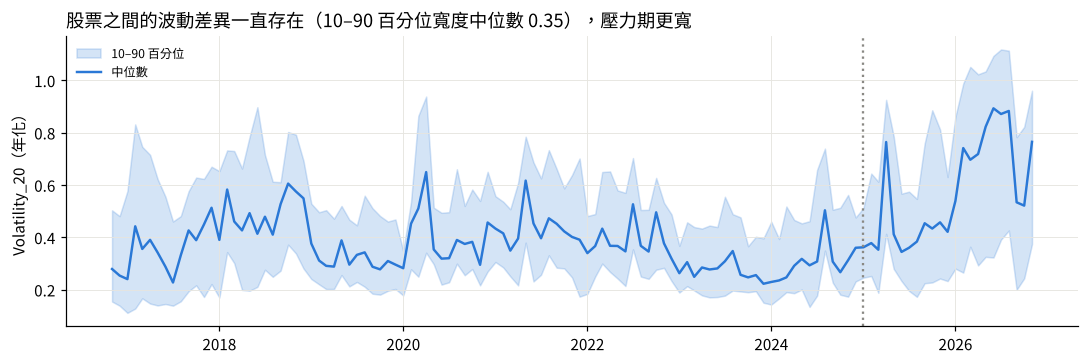

In [7]:
x = smp[smp.is_decision & smp.eligible]                      # 決策日合格樣本
q = x.groupby(x.date.dt.to_period("M")).hv20_L20.quantile([.1, .5, .9]).unstack()  # 每月分位數
fig, ax = plt.subplots(figsize=(10, 3.4))                    # 開圖
t = q.index.to_timestamp(); ax.fill_between(t, q[.1], q[.9], color=BLUE, alpha=.2, label="10–90 百分位"); ax.plot(t, q[.5], color=BLUE, lw=1.6, label="中位數")  # 帶狀與中位數
ax.axvline(HOLDOUT_START, color=GREY, ls=":"); ax.legend(frameon=False, fontsize=8); ax.set_ylabel("Volatility_20（年化）")  # 標記
ax.set_title(f"股票之間的波動差異一直存在（10–90 百分位寬度中位數 {(q[.9]-q[.1]).median():.2f}），壓力期更寬")  # 標題
save(fig, "03_dispersion.png")                               # 存圖

## G. 冗餘結構
用 1 − |Spearman ρ| 當距離做平均連結分群，切在 |ρ| = 0.7（範本的門檻）。同一群的特徵表達的是幾乎相同的排序：
線性模型很難把它們分開，樹模型則會任意挑一個。

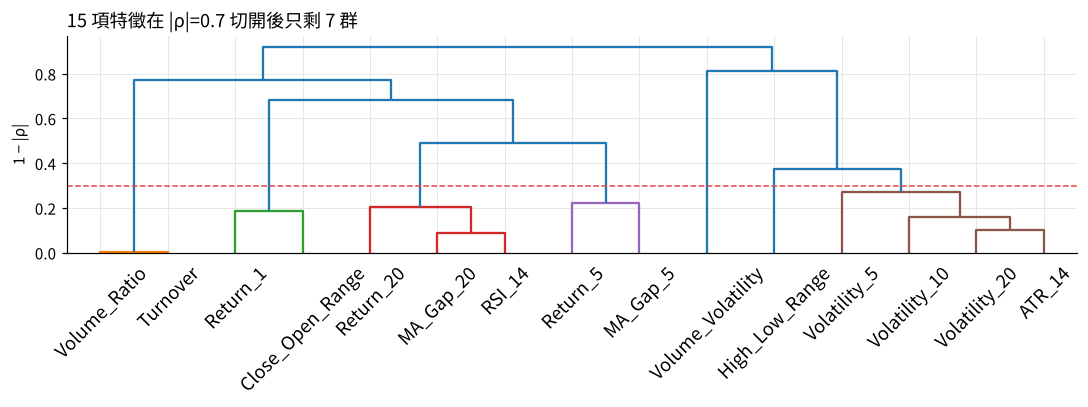

,同一群的特徵
1,"[Volume_Ratio, Turnover]"
2,"[Return_1, Close_Open_Range]"
3,"[Return_20, MA_Gap_20, RSI_14]"
4,"[Return_5, MA_Gap_5]"
5,"[Volatility_5, Volatility_10, Volatility_20, A..."
6,[High_Low_Range]
7,[Volume_Volatility]


In [8]:
cm = smp[smp.date < HOLDOUT_START][F].rank().corr().abs()    # 開發期特徵的 |Spearman| 相關
cm.index = cm.columns = [NM[short(c)] for c in F]            # 換成文件名稱
Z = linkage(squareform(1 - cm.values, checks=False), "average")  # 平均連結
cl = fcluster(Z, t=0.3, criterion="distance")                # 切在距離 0.3（|ρ| = 0.7）
fig, ax = plt.subplots(figsize=(10, 3.8))                    # 開圖
dendrogram(Z, labels=cm.index.tolist(), ax=ax, color_threshold=0.3, leaf_rotation=45); ax.axhline(0.3, color=RED, ls="--", lw=1)  # 樹狀圖與切線
ax.set_ylabel("1 − |ρ|"); ax.set_title(f"15 項特徵在 |ρ|=0.7 切開後只剩 {len(set(cl))} 群")  # 標題
save(fig, "03_redundancy.png")                               # 存圖
groups = pd.Series(cm.index, index=cl).groupby(level=0).apply(list)  # 各群成員
display(groups.to_frame("同一群的特徵"))                      # 顯示

## H. 持續性與排名穩定度
每週調整一次，所以特徵的排序至少要撐過一個決策週期（5 個交易日）才有用。左：每檔內部的自我相關（中位數）；
右：相鄰兩個決策日之間的橫斷面排名相關。

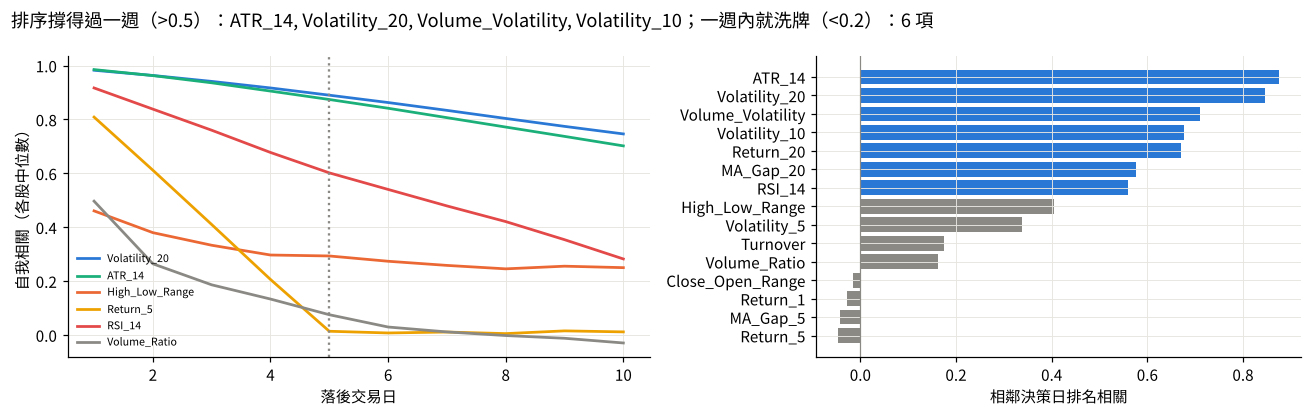

,相鄰決策日排名相關
Return_5,-0.05
MA_Gap_5,-0.04
Return_1,-0.03
Close_Open_Range,-0.01
Volume_Ratio,0.16
Turnover,0.17
Volatility_5,0.34
High_Low_Range,0.41
RSI_14,0.56
MA_Gap_20,0.58


In [9]:
sel = ["hv20_L20", "atr_p_L20", "hl_L20", "ret5_L20", "rsi_L20", "vol_ratio_L20"]  # 代表性特徵
d = smp[smp.date < HOLDOUT_START].sort_values(["sid", "date"])  # 開發期
acf = {c: [d.groupby("sid")[c].apply(lambda s: s.autocorr(k)).median() for k in range(1, 11)] for c in sel}  # 每檔內部自我相關的中位數
dec = d[d.is_decision]                                       # 決策日
rk = {c: dec.pivot(index="date", columns="sid", values=c).rank(axis=1).pipe(lambda P: P.corrwith(P.shift(1), axis=1).mean()) for c in F}  # 相鄰決策日排名相關
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})  # 兩張
for c, col in zip(sel, [BLUE, AQUA, ORANGE, YELLOW, RED, GREY]): axs[0].plot(range(1, 11), acf[c], color=col, lw=1.8, label=NM[short(c)])  # 自我相關線
axs[0].axvline(H, color=GREY, ls=":"); axs[0].set_xlabel("落後交易日"); axs[0].set_ylabel("自我相關（各股中位數）"); axs[0].legend(frameon=False, fontsize=7)  # 標籤
r = pd.Series(rk).rename(lambda c: NM[short(c)]).sort_values(); axs[1].barh(r.index, r.values, color=[BLUE if v > .5 else GREY for v in r.values])  # 排名穩定度
axs[1].set_xlabel("相鄰決策日排名相關"); axs[1].axvline(0, color=GREY, lw=.8)  # 標籤
fig.suptitle(f"排序撐得過一週（>0.5）：{', '.join(r[r > .5].index[::-1][:4])}；一週內就洗牌（<0.2）：{len(r[r < .2])} 項", x=.01, ha="left", fontsize=12)  # 依數字產生總標題
save(fig, "03_persistence.png")                              # 存圖
display(r.round(2).to_frame("相鄰決策日排名相關"))            # 顯示

## 特徵表交付
特徵表（`data/processed/samples.parquet`）以（股票, 日期）為鍵，含 15 項特徵 × 3 種回看期。
前面的檢查回答了「能不能算、有沒有偷看未來、能不能跨股票比較」；能不能預測由 `05_evaluation` 判斷。

**已知限制**：RSI 用簡單平均（不是 Wilder 平滑）；Volume_Ratio 與 Turnover 幾乎是同一個量；
股票池固定為今日名單；還原權值依賴 FinMind 的除權息與減資參考價，分割事件需手動補（0050）。